In [1]:

import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random
import tensorflow as tf


from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from PIL import Image

In [2]:
train_dir = "../dataset/Train_Set"
test_dir = "../dataset/Test_Set"

print(os.listdir(train_dir))
print(os.listdir(test_dir))

['Aman', 'Lainnya', 'Rusak']
['test_00001.jpg', 'test_00002.jpg', 'test_00003.jpg', 'test_00004.jpg', 'test_00005.jpeg', 'test_00006.jpg', 'test_00007.jpg', 'test_00008.jpg', 'test_00009.jpg', 'test_00010.jpg', 'test_00011.png', 'test_00012.jpg', 'test_00013.jpg', 'test_00014.jpg', 'test_00015.jpg', 'test_00016.jpg', 'test_00017.jpg', 'test_00018.jpg', 'test_00019.jpg', 'test_00020.jpg', 'test_00021.jpg', 'test_00022.jpg', 'test_00023.jpg', 'test_00024.jpg', 'test_00025.jpg', 'test_00026.jpg', 'test_00027.jpg', 'test_00028.png', 'test_00029.jpg', 'test_00030.jpg', 'test_00031.jpg', 'test_00032.jpg', 'test_00033.jpg', 'test_00034.jpg', 'test_00035.jpg', 'test_00036.jpg', 'test_00037.jpeg', 'test_00038.jpg', 'test_00039.jpg', 'test_00040.jpg', 'test_00041.jpg', 'test_00042.jpg', 'test_00043.jpg', 'test_00044.jpg', 'test_00045.jpg', 'test_00046.jpg', 'test_00047.png', 'test_00048.jpg', 'test_00049.jpg', 'test_00050.png', 'test_00051.jpg', 'test_00052.jpg', 'test_00053.jpg', 'test_00054.jp

In [3]:
classes = ["Aman", "Lainnya", "Rusak"]

counts = []

for class_name in classes:
    class_path = os.path.join(train_dir, class_name)
    count = len(os.listdir(class_path))
    counts.append(count)


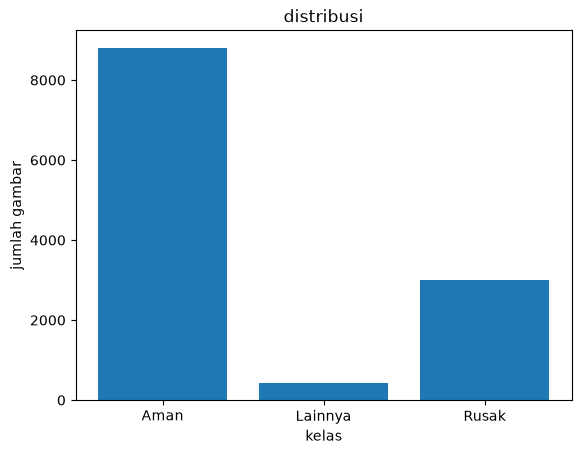

{'Aman': 8800, 'Lainnya': 423, 'Rusak': 3001}


In [4]:
plt.Figure(figsize=(8,5))
plt.bar(classes, counts)

plt.title("distribusi")
plt.xlabel("kelas")
plt.ylabel("jumlah gambar")
plt.show()

print(dict(zip(classes, counts)))

In [5]:
for class_name in classes:
    class_path = os.path.join(train_dir,class_name)
    sizes = []
    for filename in os.listdir(class_path)[:100]:
        image_path = os.path.join(class_path, filename)
        try:
            img = Image.open(image_path)
            sizes.append( img.size)
        except:
            pass
    print(class_name)
    print(set(sizes))
    print()

Aman
{(150, 200), (1061, 597), (1910, 1000), (119, 200), (323, 149), (1600, 713), (1792, 1024), (800, 800), (1280, 720), (640, 640), (1500, 900), (1536, 1024), (612, 459), (986, 490), (966, 966), (165, 200), (962, 962), (512, 512), (479, 341), (809, 430), (2519, 1665), (1712, 963), (1500, 1500), (416, 416), (1000, 500), (200, 50), (1920, 1080), (1024, 683), (319, 181), (626, 338), (1000, 1000), (960, 540), (912, 1000), (1024, 640), (720, 720), (224, 224), (734, 487), (200, 150), (784, 1168), (1500, 1072), (1024, 1024), (339, 143), (966, 644), (327, 181), (740, 435), (864, 834), (612, 408), (1130, 648), (339, 173), (1536, 866)}

Lainnya
{(261, 400), (117, 200), (252, 400), (150, 200), (200, 100), (200, 109), (400, 259), (400, 372), (400, 262), (248, 400), (232, 400), (254, 400), (400, 329), (200, 63), (228, 400), (200, 182), (400, 219), (256, 400), (278, 400), (90, 200), (377, 400), (400, 341), (400, 332), (400, 277), (165, 200), (200, 191), (400, 356), (400, 243), (400, 362), (300, 400

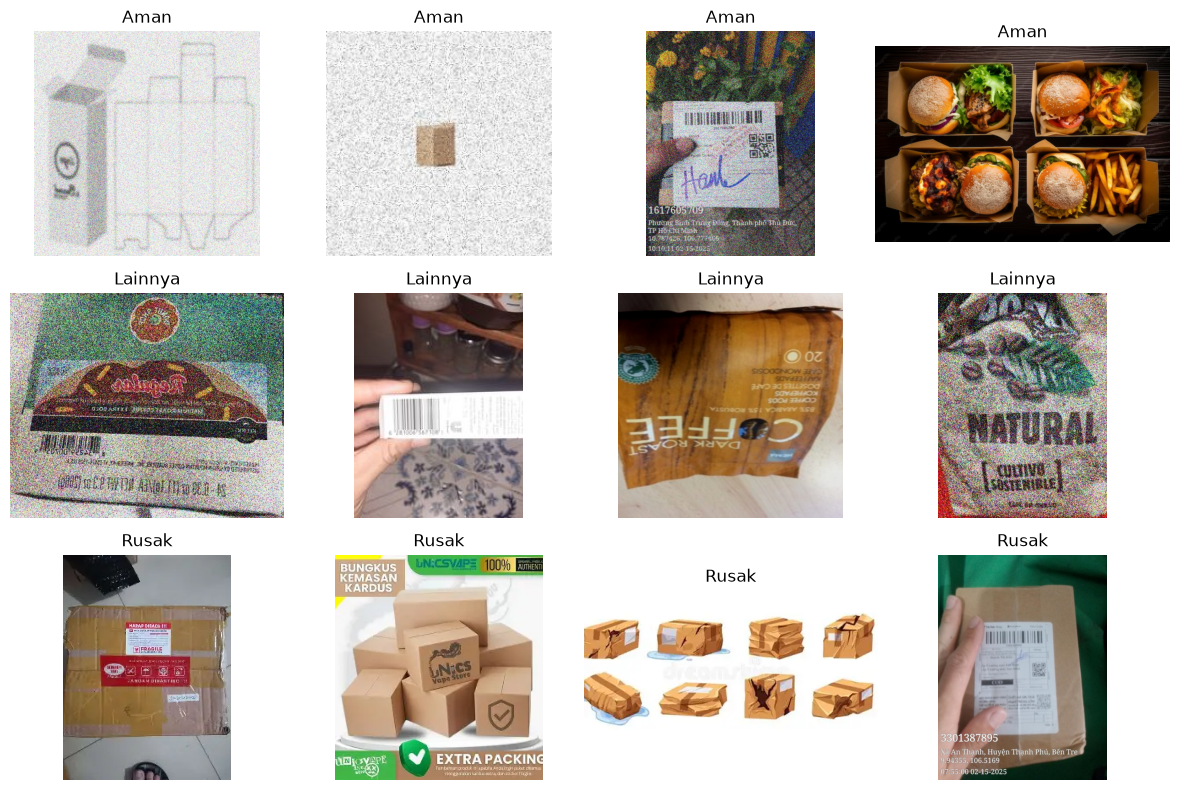

In [6]:
plt.figure(figsize=(12, 8))

for i, class_name in enumerate(classes):
    class_path = os.path.join(train_dir, class_name)
    files = os.listdir(class_path)
    samples = random.sample(files , 4)
    for j, filename in enumerate(samples):
        image_path = os.path.join(class_path, filename)
        img = Image.open(image_path)
        position = i*4 +j + 1
        plt.subplot(3, 4,position)
        plt.imshow(img)
        plt.title(class_name)
        plt.axis("off")
plt.tight_layout()
plt.show()

In [7]:
train_dir = "../dataset/Train_Set"

classes = ["Aman", "Lainnya", "Rusak"]

image_paths = []
labels = []

for class_name in classes:

    class_dir = os.path.join(train_dir, class_name)

    for filename in os.listdir(class_dir):

        image_path = os.path.join(class_dir, filename)

        image_paths.append(image_path)
        labels.append(class_name)

print("Total gambar:", len(image_paths))

Total gambar: 12224


In [8]:
df = pd.DataFrame({
    "filepath": image_paths,
    "label": labels
})

df.head()

,filepath,label
0,../dataset/Train_Set\Aman\Aman_00001.jpg,Aman
1,../dataset/Train_Set\Aman\Aman_00002.png,Aman
2,../dataset/Train_Set\Aman\Aman_00003.jpg,Aman
3,../dataset/Train_Set\Aman\Aman_00004.jpg,Aman
4,../dataset/Train_Set\Aman\Aman_00005.jpg,Aman


In [9]:
print(df["label"].value_counts())

label
Aman       8800
Rusak      3001
Lainnya     423
Name: count, dtype: int64


### encode


In [10]:
label_map = {
    "Aman": 0,
    "Lainnya": 1,
    "Rusak": 2
}

df["label_id"] = df["label"].map(label_map)
df.head()

,filepath,label,label_id
0,../dataset/Train_Set\Aman\Aman_00001.jpg,Aman,0
1,../dataset/Train_Set\Aman\Aman_00002.png,Aman,0
2,../dataset/Train_Set\Aman\Aman_00003.jpg,Aman,0
3,../dataset/Train_Set\Aman\Aman_00004.jpg,Aman,0
4,../dataset/Train_Set\Aman\Aman_00005.jpg,Aman,0


### split

In [11]:
train_df, val_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["label_id"]
)
print("Training:", len(train_df))
print("Validation:", len(val_df))

Training: 9779
Validation: 2445


In [12]:
print("TRAIN")
print(train_df["label"].value_counts())

print("\nVALIDATION")
print(val_df["label"].value_counts())

TRAIN
label
Aman       7040
Rusak      2401
Lainnya     338
Name: count, dtype: int64

VALIDATION
label
Aman       1760
Rusak       600
Lainnya      85
Name: count, dtype: int64


In [13]:
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1, 2]),
    y=train_df["label_id"]
)

class_weights = dict(enumerate(class_weights))

print(class_weights)

{0: np.float64(0.4630208333333333), 1: np.float64(9.643984220907297), 2: np.float64(1.3576287657920312)}


In [14]:
bad_files = []

for filepath in df["filepath"]:
    try:
        img = Image.open(filepath)
        img.verify()
    except:
        bad_files.append(filepath)

print("Jumlah file rusak:", len(bad_files))

if len(bad_files) > 0:
    print(bad_files[:10])

Jumlah file rusak: 0


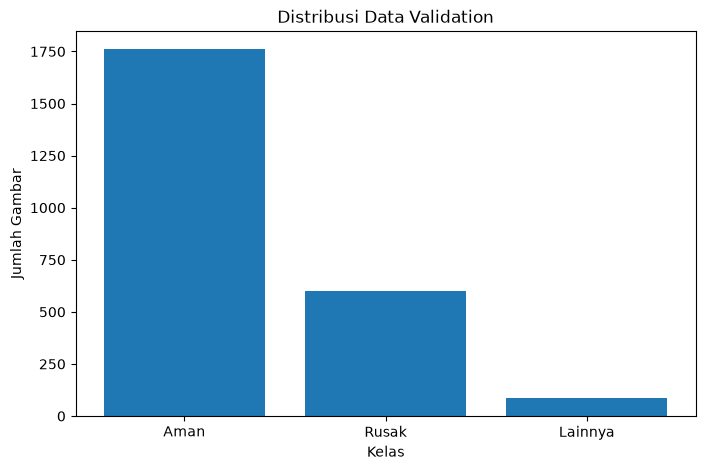

In [15]:
plt.figure(figsize=(8, 5))
val_counts = val_df["label"].value_counts()
plt.bar(val_counts.index, val_counts.values)
plt.title("Distribusi Data Validation")
plt.xlabel("Kelas")
plt.ylabel("Jumlah Gambar")
plt.show()